# Event betas: how asset prices respond to prediction market odds
Requires live data (`python scripts/fetch_data.py`). For each asset and event:
r = a + b · (Δp / 10) + e, Newey West errors, changes measured between NYSE trading days.

In [2]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from altinfo import gap, satellite, earnings, scoring, charts, valuation, eventbeta as eb
from altinfo.charts import NAVY, BLUE, RED, GREY
charts.style()
RAW = ROOT / "data" / "raw"
SNAP = json.load(open(ROOT / "data" / "snapshot_2026-11-09.json"))
LIVE = (RAW / "prices.csv").exists()
print("Mode:", "LIVE (data/raw)" if LIVE else "SNAPSHOT (figures of 9 Nov 2026; run scripts/fetch_data.py for live data)")
def kalshi_live(series):
    """Open Kalshi markets of a series with a mid price (bid/ask midpoint, else last trade)."""
    km = pd.read_csv(RAW / "kalshi_markets.csv")
    m = km[km["series"] == series].copy()
    mid = (m["yes_bid_dollars"] + m["yes_ask_dollars"]) / 2
    tight = (m["yes_ask_dollars"] - m["yes_bid_dollars"]).le(0.10) & m["yes_ask_dollars"].gt(0)
    m["mid"] = mid.where(tight, m["last_price_dollars"])
    return m
def poly_live(pattern):
    pm = pd.read_csv(RAW / "polymarket_markets.csv")
    return pm[pm.question.str.contains(pattern, case=False, na=False, regex=True) & (pm.closed != True)].sort_values("volume", ascending=False)
def live_calls(today="2026-11-10"):
    """The calls registered in the reports, with the market probability updated to the latest live data."""
    calls = pd.DataFrame(SNAP["calls"]).assign(asset=["NVDA", "BRENT"], date=["2026-11-17", "2026-11-30"],
                                                confidence="medium", date_asof=pd.Timestamp(today))
    calls["market_week_ago"] = [SNAP["nvda"]["real"]["polymarket_beat_history"]["2026-11-03"], np.nan]
    if LIVE:
        cd = pd.read_csv(RAW / "kalshi_candles.csv", parse_dates=["date"])
        cd = cd[cd.ticker.str.startswith("KXBRENTMON-26NOV30")].copy()
        cd["strike"] = cd.ticker.str.extract(r"-T([\d.]+)$")[0].astype(float)
        daily = cd.dropna(subset=["price"]).groupby("date").apply(lambda d: gap.ladder_prob_above(d.strike, d.price, 96), include_groups=False)
        bm = kalshi_live("KXBRENTMON").dropna(subset=["floor_strike", "mid"])
        calls.loc[calls.asset == "BRENT", "market"] = gap.ladder_prob_above(bm.floor_strike, bm.mid, 96)
        calls.loc[calls.asset == "BRENT", "market_week_ago"] = daily.loc[:pd.Timestamp(today) - pd.Timedelta(days=7)].iloc[-1]
        nb_ = poly_live(r"N[Vv][Ii][Dd][Ii][Aa].*beat|NVDA.*beat")
        if len(nb_):
            calls.loc[calls.asset == "NVDA", "market"] = float(nb_["price"].iloc[0])
    return calls
def load_prices():
    p = pd.read_csv(RAW / "prices.csv")
    p["date"] = pd.to_datetime(p["date"], format="mixed").dt.normalize()
    return p.pivot_table(index="date", columns="ticker", values="close").sort_index()

Mode: LIVE (data/raw)


In [3]:
kal = pd.read_csv(RAW / "kalshi_fed.csv"); poly = pd.read_csv(RAW / "polymarket_history.csv")
rets = eb.asset_returns(pd.read_csv(RAW / "prices.csv")); cal = rets["SPY"].dropna().index
MEET = {"25JUL": "2025-07-30", "25SEP": "2025-09-17", "25OCT": "2025-10-29", "25DEC": "2025-12-10", "26JAN": "2026-01-28",
        "26MAR": "2026-03-18", "26APR": "2026-04-29", "26JUN": "2026-06-17", "26JUL": "2026-07-29", "26SEP": "2026-09-16",
        "26OCT": "2026-10-28", "26DEC": "2026-12-09", "27JAN": "2027-01-27", "27MAR": "2027-03-17"}
fed = eb.fed_expected_move(kal, MEET, calendar=cal)
probs = eb.event_probs(poly)
EV = [e for e in ["us_invades_iran", "hormuz_normal", "iran_regime_falls", "china_invades_taiwan", "us_recession_2026"] if e in probs]
shocks = eb.event_changes(probs[EV], calendar=cal); shocks["fed_move"] = fed["dE"]
UNITS = {e: 10.0 for e in shocks}
ASSETS = [a for a in ["NVDA", "SMH", "TSM", "SPY", "QQQ", "VGK", "EEM", "EWT", "TLT", "HYG", "GLD", "BZ=F", "XLE", "ITA", "JETS", "UUP", "^TNX", "^VIX"] if a in rets]
br = eb.event_betas(rets[ASSETS], shocks, scale=UNITS)
LAB = {"us_invades_iran": "US invades Iran", "hormuz_normal": "Hormuz reopens", "iran_regime_falls": "Iran regime falls",
       "china_invades_taiwan": "China invades Taiwan", "us_recession_2026": "US recession 2026", "fed_move": "Fed move (+10bp)"}
pd.DataFrame({"Event": [LAB[c] for c in shocks.columns], "Trading days with data": shocks.notna().sum().values})

Event,Trading days with data
US invades Iran,253
Hormuz reopens,126
Iran regime falls,246
China invades Taiwan,316
US recession 2026,272
Fed move (+10bp),350


**How to read it.** The events we test and how many trading days of data each one has. Events that started recently, such as the Hormuz market, have fewer days and less reliable results.

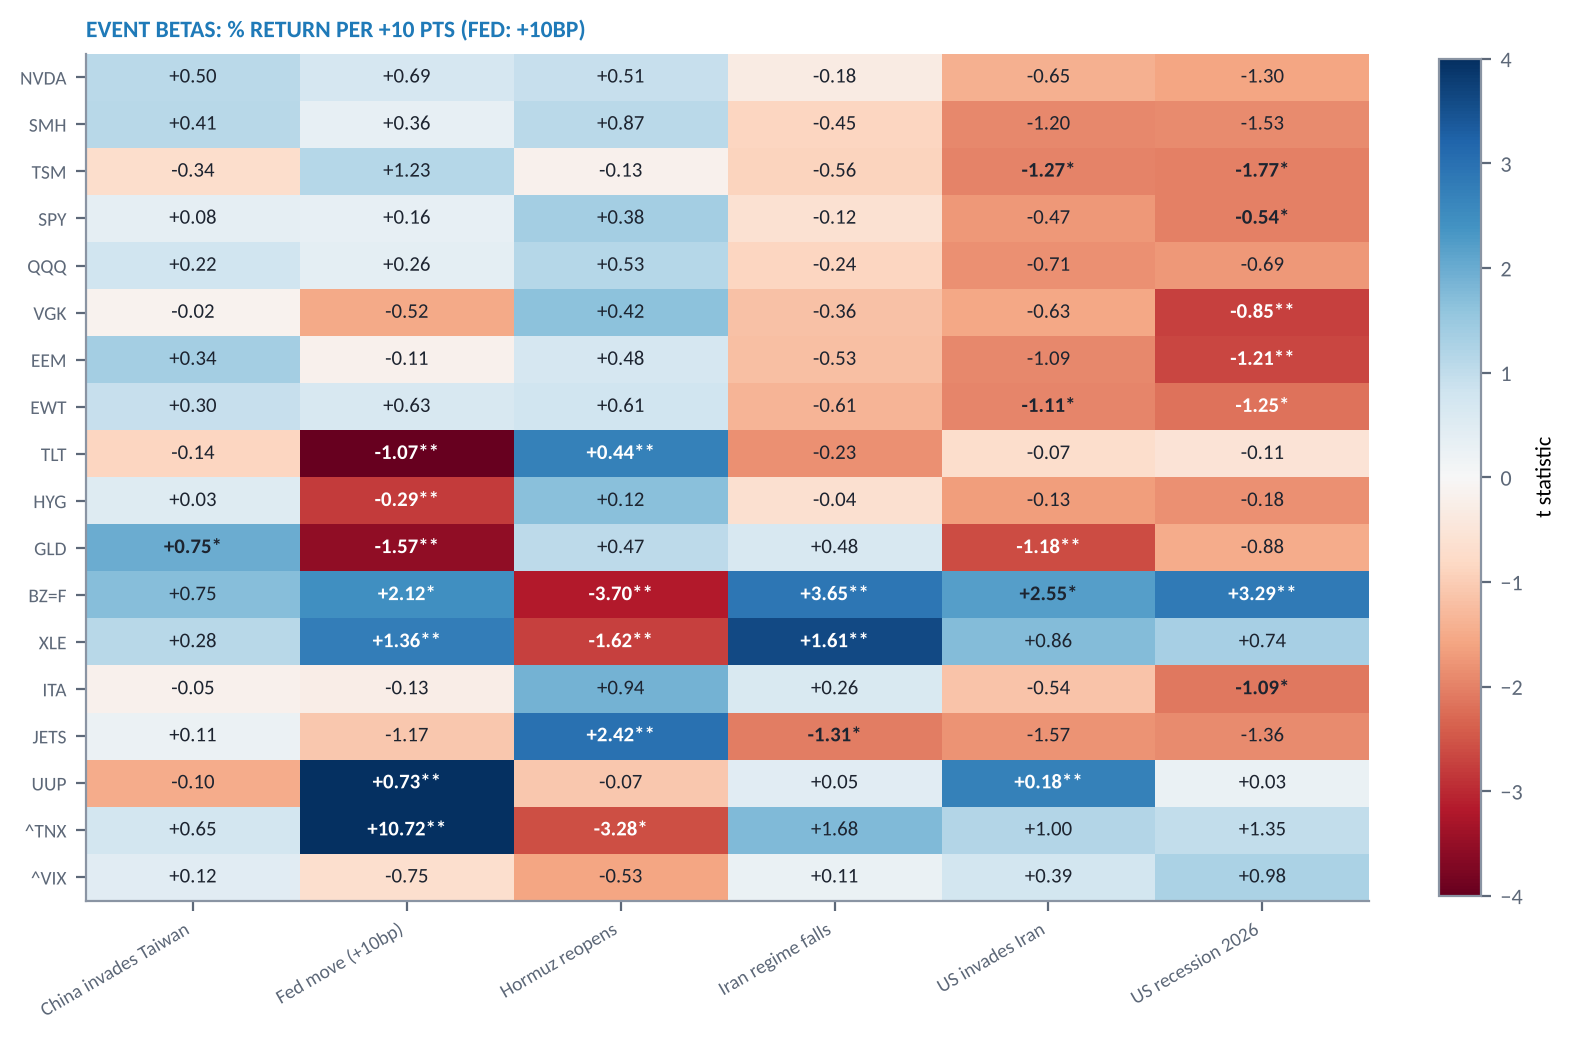

In [4]:
piv = br.pivot(index="asset", columns="event", values="beta").reindex(index=ASSETS)
tv = br.pivot(index="asset", columns="event", values="t").reindex(index=ASSETS, columns=piv.columns)
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(tv.clip(-4, 4).values, cmap="RdBu", vmin=-4, vmax=4, aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v, t = piv.iat[i, j], tv.iat[i, j]
        if not np.isnan(v):
            col = charts.text_on(im.cmap(im.norm(np.clip(t, -4, 4))))
            ax.text(j, i, f"{v:+.2f}{'**' if abs(t) > 2.58 else '*' if abs(t) > 1.96 else ''}", ha="center", va="center",
                    fontsize=7.5, color=col, weight="bold" if abs(t) > 1.96 else "normal")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels([LAB.get(c, c) for c in piv.columns], rotation=30, ha="right", fontsize=7)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index, fontsize=7); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.03, label="t statistic"); ax.set_title("EVENT BETAS: % RETURN PER +10 PTS (FED: +10BP)"); plt.show()

**How to read it.** Each cell is the average return of an asset (rows) on a day when the probability of an event (columns) rose by 10 points. Blue means the asset tends to rise, red that it tends to fall; the darker the colour, the more reliable the result. One star means significant at 5%, two stars at 1%. For example, Brent futures fall when the odds of Hormuz reopening rise, and rise when the odds of a US invasion of Iran rise.

In [5]:
# Out of sample: fit on the first 60% of days, predict returns on days when an event moved 5+ points
X = shocks.div(pd.Series(UNITS)).fillna(0); common = rets[ASSETS].index.intersection(X.index)
Y, X = rets[ASSETS].loc[common], X.loc[common]; cut = common[int(len(common) * 0.6)]
pv, rv = [], []
for a in ASSETS:
    y = Y[a]; m = y.notna(); tr, te = m & (y.index < cut), m & (y.index >= cut)
    coef = np.linalg.lstsq(np.column_stack([np.ones(tr.sum()), X[tr].values]), y[tr].values, rcond=None)[0]
    p = coef[0] + X[te].values @ coef[1:]; big = (X[te].abs().max(axis=1) * 10 >= 5).values
    pv += list(p[big]); rv += list(y[te].values[big])
pv, rv = np.array(pv), np.array(rv)
print(f"Out of sample from {cut:%d %b %Y}: sign hit rate {(np.sign(pv) == np.sign(rv)).mean():.0%}, correlation {np.corrcoef(pv, rv)[0, 1]:.2f}")

Out of sample from 07 Jan 2026: sign hit rate 42%, correlation -0.07


**How to read it.** A test on data the model had not seen: betas estimated before January 2026 are used to predict returns on later days with large moves in the odds. A hit rate near 50% and a correlation near zero mean they do not predict returns, so we use them as a map of risk, not as a trading signal.

**Reading.** In sample, several betas are significant (for example oil and energy stocks on the Hormuz and Iran
markets). Out of sample, betas estimated before January 2026 do not predict returns on later event days: the relation
changes as the war evolves. Event betas are therefore used as a **risk map** (what a portfolio is exposed to today,
re-estimated on rolling windows), not as a trading signal. The edge of the platform comes from the physical layer.

In [7]:
PORT = {"US 60/40": {"SPY": .6, "TLT": .4}, "AI growth": {"QQQ": .5, "NVDA": .15, "SMH": .15, "EWT": .1, "TLT": .1},
        "Energy tilt": {"SPY": .45, "XLE": .25, "BZ=F": .1, "TLT": .2}}
expo = pd.DataFrame({p: eb.portfolio_exposure(br, {a: w for a, w in v.items() if a in ASSETS}) for p, v in PORT.items()}).T
SCEN = {"Deal signed": {"hormuz_normal": 25, "us_invades_iran": -15}, "Talks collapse": {"hormuz_normal": -20, "us_invades_iran": 20}}
for s, d in SCEN.items():
    expo[s] = [eb.scenario(expo.loc[p], {k: v for k, v in d.items() if k in expo}, UNITS) for p in expo.index]
view = expo.rename(columns=LAB).apply(lambda c: c.map("{:+.2f}".format))
view.index.name = "Portfolio (% per +10 pts; scenarios in %)"
view

Portfolio (% per +10 pts; scenarios in %),China invades Taiwan,Fed move (+10bp),Hormuz reopens,Iran regime falls,US invades Iran,US recession 2026,Deal signed,Talks collapse
US 60/40,-0.01,-0.33,+0.40,-0.16,-0.31,-0.36,+1.47,-1.43
AI growth,+0.26,+0.24,+0.58,-0.30,-0.75,-0.91,+2.56,-2.65
Energy tilt,+0.15,+0.41,-0.52,+0.67,+0.24,+0.25,-1.66,+1.52


**How to read it.** Three model portfolios. The first columns show how much each portfolio moves for a 10 point rise in each event probability; the last two show the total move under two scenarios: a deal signed (Hormuz reopens) and talks collapsing. This is how a fund sees which events it is exposed to.